# Notebook 03 - Exploratory Analysis

This notebook uses clean NIR and MIR outputs to run PCA and compute Pearson correlations between principal components and soil attributes.

## Quick Start (for new users)

1. Ensure Notebook 02 finished successfully and generated `02_nir_clean.csv`, `02_mir_clean.csv`, and `02_processing_metadata.json` in `Outputs/pipeline/`.
2. Run all cells in order.
3. Confirm outputs in `Outputs/pipeline/`: `03_nir_pca_scores.csv`, `03_mir_pca_scores.csv`, `03_pearson_pcs_vs_targets.csv`, `03_pca_explained_variance.csv`, `03_eda_metadata.json`, and `03_user_report.txt`.
4. Review figures in `Outputs/pipeline/Figures/`: `03_pca_scatter_domains.png` and `03_pearson_heatmap.png`.
5. If any upstream artifact is missing, run Notebook 02 again with the same output folder before retrying.
6. If the notebook reports missing packages, launch the project with `launch_pipeline_vscode.bat` and reopen VS Code.

In [3]:
import importlib.util
import sys

RUNTIME_PACKAGES = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
}

missing_packages = [pkg_name for pkg_name, module_name in RUNTIME_PACKAGES.items() if importlib.util.find_spec(module_name) is None]
if missing_packages:
    print('Missing dependencies detected:')
    for package_name in missing_packages:
        print(f'  - {package_name}')
    raise RuntimeError(
        'This notebook cannot continue because required packages are missing. '
        'Run launch_pipeline_vscode.bat from the repository root, reopen VS Code, and run this notebook again.'
    )

if '.venv' not in str(sys.executable).lower():
    print('Warning: active interpreter is not .venv. For non-technical users, run launch_pipeline_vscode.bat and reopen VS Code.')
else:
    print('Environment check passed: .venv interpreter detected and required packages are available.')

Environment check passed: .venv interpreter detected and required packages are available.


## Theoretical Framework

This notebook runs **Principal Component Analysis (PCA)** on processed spectra and computes Pearson correlations between PC scores and soil attributes. The objective is both to reduce dimensionality (thousands of bands to a few PCs) and to explain what fraction of spectral variability is associated with measurable analytical soil properties.

**Sequence guard:** this notebook requires `02_nir_clean.csv`, `02_mir_clean.csv`, and `02_processing_metadata.json` as prerequisite artifacts from the previous notebook.

In [4]:
import time
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from spectral_pipeline_utils import get_spectral_columns, pca_svd, run_stamp, write_json

OUTPUT_DIR = ROOT / 'Outputs' / 'pipeline'
FIG_DIR = OUTPUT_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    OUTPUT_DIR / '02_nir_clean.csv',
    OUTPUT_DIR / '02_mir_clean.csv',
    OUTPUT_DIR / '02_processing_metadata.json',
]
for file in required_files:
    if not file.exists():
        raise FileNotFoundError(
            f'Missing upstream artifact: {file}. Run Stage 02 first using the same output folder.'
        )

print('Stage 03 preflight passed: Stage 02 artifacts are available.')

Stage 03 preflight passed: Stage 02 artifacts are available.


## Block 1 - Domain-wise PCA and Pearson correlation with soil attributes

### PCA in soil spectroscopy

**Principal Component Analysis (PCA)** transforms the spectral matrix $X$ (n samples x p bands) into a lower-dimensional space where each principal component (PC) is a linear combination of original bands that maximizes explained variance.

In soil spectroscopy, this is useful to:
1. **Visualize structure**: spectrally similar soil groups emerge as clusters in PC1-PC2 space.
2. **Reduce redundancy**: adjacent bands are highly correlated; the first 8 PCs often capture most spectral variance.
3. **Support clustering**: Notebook 04 uses NIR scores for sample grouping (k-means in PC space).
4. **Support quality diagnostics**: score distributions can reveal residual outliers or unintended sampling-condition clusters.

> **Fabricio et al. (2015)**, *"Quantitative assessment of soil properties"*, applied PCA on Vis-NIR and MIR reflectance of Brazilian soils and reported strong links between early PCs and texture-related variation.

> **Dematte et al. (2022)** describe PCA as a core exploratory tool to identify diagnostic minerals in spectral space and separate major soil behavior groups before predictive modeling.

### Pearson correlation: PCs vs attributes

For each (domain x attribute x PC) combination, the notebook computes Pearson's correlation coefficient $r$. This helps to:
- Identify which PCs are most informative for each soil property.
- Decide whether both domains should be kept or one domain is more predictive for Notebook 05.
- Check dataset physical consistency (for example, PCs linked to clay should show meaningful absorption-structure influence in known spectral regions).

### Generated artifacts

| File | Content | Pipeline use |
|---------|-----------|-------------------|
| `03_nir_pca_scores.csv` | PC1-PC8 scores per sample (NIR domain) | Notebook 04 input (clustering) |
| `03_mir_pca_scores.csv` | PC1-PC8 scores per sample (MIR domain) | Reference and comparative analysis |
| `03_pearson_pcs_vs_targets.csv` | Pearson $r$ for each (domain, target, PC) | Physical interpretation and reporting |
| `03_pca_explained_variance.csv` | Explained variance per PC and domain | Component selection for modeling |
| `03_pca_scatter_domains.png` | PC1 vs PC2 scatter for NIR and MIR | Visual structure QC |
| `03_pearson_heatmap.png` | Heatmap of $r$ (domain x target vs PC) | Result communication |

In [5]:
def pca_and_corr(path: Path, domain: str, n_comp: int = 8):
    t0 = time.perf_counter()
    try:
        print(f"[Stage 03] Running PCA for {domain.upper()} from {path.name}...")
        df = pd.read_csv(path, low_memory=False)
        meta_cols, spectral_cols, wl = get_spectral_columns(df)

        meta = df[meta_cols].copy()
        X = df[spectral_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
        finite_mean = np.nanmean(X) if np.isfinite(X).any() else 0.0
        X = np.nan_to_num(X, nan=finite_mean, posinf=finite_mean, neginf=finite_mean)

        pca_out = pca_svd(X, n_comp)
        scores = pca_out['scores']
        ev = pca_out['explained_variance']
        pc_names = [f'PC{i+1}' for i in range(scores.shape[1])]

        score_df = pd.DataFrame(scores, columns=pc_names)
        if 'ID_Unico' in meta.columns:
            score_df.insert(0, 'sample_id', meta['ID_Unico'].values)
        else:
            score_df.insert(0, 'sample_id', np.arange(1, len(score_df) + 1))

        target_candidates = ['Clay_gkg', 'Sand_gkg', 'C_gkg', 'OM_gkg']
        targets = [c for c in target_candidates if c in meta.columns]
        corr_rows = []
        for t in targets:
            y = pd.to_numeric(meta[t], errors='coerce').to_numpy(dtype=float)
            for j, pc in enumerate(pc_names):
                x = scores[:, j]
                valid = np.isfinite(x) & np.isfinite(y)
                r = np.corrcoef(x[valid], y[valid])[0, 1] if valid.sum() > 2 else np.nan
                corr_rows.append({'domain': domain, 'target': t, 'pc': pc, 'pearson_r': float(r) if np.isfinite(r) else np.nan})

        corr_df = pd.DataFrame(corr_rows)
        ev_df = pd.DataFrame({'domain': domain, 'pc': pc_names, 'explained_variance': ev[:len(pc_names)]})

        elapsed = time.perf_counter() - t0
        print(f"[Stage 03] {domain.upper()} PCA done in {elapsed:.1f}s")
        return score_df, corr_df, ev_df, wl, float(elapsed)
    except Exception as exc:
        raise RuntimeError(
            f"Stage 03 failed while processing {domain.upper()} from '{path}'. Details: {exc}"
        ) from exc


stage3_t0 = time.perf_counter()
nir_scores, nir_corr, nir_ev, nir_wl, nir_seconds = pca_and_corr(OUTPUT_DIR / '02_nir_clean.csv', 'nir', n_comp=8)
mir_scores, mir_corr, mir_ev, mir_wl, mir_seconds = pca_and_corr(OUTPUT_DIR / '02_mir_clean.csv', 'mir', n_comp=8)
print(f"[Stage 03] Total PCA + correlation time: {time.perf_counter() - stage3_t0:.1f}s")

all_corr = pd.concat([nir_corr, mir_corr], axis=0, ignore_index=True)
all_ev = pd.concat([nir_ev, mir_ev], axis=0, ignore_index=True)

nir_scores.to_csv(OUTPUT_DIR / '03_nir_pca_scores.csv', index=False)
mir_scores.to_csv(OUTPUT_DIR / '03_mir_pca_scores.csv', index=False)
all_corr.to_csv(OUTPUT_DIR / '03_pearson_pcs_vs_targets.csv', index=False)
all_ev.to_csv(OUTPUT_DIR / '03_pca_explained_variance.csv', index=False)

print('Exported PCA scores and Pearson correlations (Stage 03)')

[Stage 03] Running PCA for NIR from 02_nir_clean.csv...
[Stage 03] NIR PCA done in 2.2s
[Stage 03] Running PCA for MIR from 02_mir_clean.csv...
[Stage 03] MIR PCA done in 0.1s
[Stage 03] Total PCA + correlation time: 2.4s
Exported PCA scores and Pearson correlations (Stage 03)


## Block 2 - Visualization: PCA scatter and correlation heatmap

### PCA scatter (PC1 vs PC2)
The PC1-PC2 projection is one of the most common exploratory views in soil spectroscopy. The point-distribution pattern can reflect:
- **Texture gradients**: sandy vs clay-rich soils may separate in PC1/PC2 due to major differences in spectral behavior.
- **Organic matter gradients**: higher organic matter can darken spectra and alter overall shape trends.
- **Spectral groups**: visible clusters suggest subpopulations that Notebook 04 can formalize.

> **Poppiel et al. (2019)**, *"Pedology and soil class mapping from proximal and remote sensed data"*, show that PCA projections from laboratory spectra can reflect pedological class structure.

### Pearson correlation heatmap
The heatmap displays matrix $r(\text{domain} \times \text{attribute}, \text{PC})$ and helps to identify:
- Which soil properties have stronger spectral signal (higher correlation with at least one PC).
- Whether NIR or MIR is more predictive for each attribute (comparing rows by domain).
- Which PCs may be redundant (similar correlation profiles across multiple attributes).

> **Fabricio et al. (2015)** report strong correlations between early PCs and texture-related properties in Brazilian soil datasets, with moderate to high values depending on variability and sampling design.

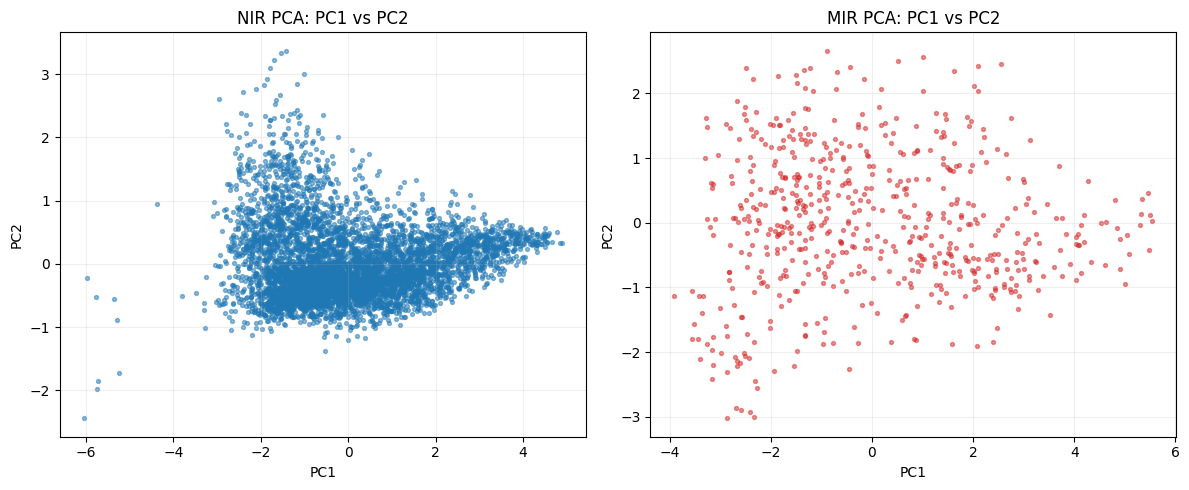

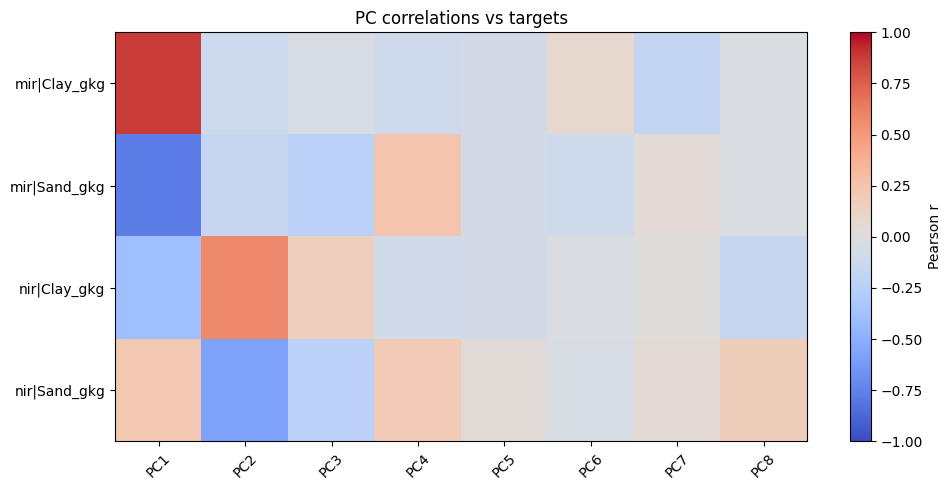

Stage 03 saved
Saved user report: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\03_user_report.txt


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(nir_scores['PC1'], nir_scores['PC2'], s=8, alpha=0.5)
axes[0].set_title('NIR PCA: PC1 vs PC2')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].grid(alpha=0.2)

axes[1].scatter(mir_scores['PC1'], mir_scores['PC2'], s=8, alpha=0.5, color='tab:red')
axes[1].set_title('MIR PCA: PC1 vs PC2')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].grid(alpha=0.2)

fig.tight_layout()
fig_path = FIG_DIR / '03_pca_scatter_domains.png'
fig.savefig(fig_path, dpi=180)
plt.show()

pivot = all_corr.pivot_table(index=['domain', 'target'], columns='pc', values='pearson_r', aggfunc='mean')
plt.figure(figsize=(10, 5))
plt.imshow(pivot.fillna(0).to_numpy(), aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson r')
plt.yticks(np.arange(len(pivot.index)), [f'{a}|{b}' for a, b in pivot.index])
plt.xticks(np.arange(len(pivot.columns)), pivot.columns, rotation=45)
plt.title('PC correlations vs targets')
plt.tight_layout()
heatmap_path = FIG_DIR / '03_pearson_heatmap.png'
plt.savefig(heatmap_path, dpi=180)
plt.show()

meta_payload = run_stamp('03_exploratory_analysis', {
    'inputs': {
        'nir_clean': str(OUTPUT_DIR / '02_nir_clean.csv'),
        'mir_clean': str(OUTPUT_DIR / '02_mir_clean.csv'),
        'stage_02_metadata': str(OUTPUT_DIR / '02_processing_metadata.json'),
    },
    'timing_seconds': {
        'nir_pca': float(nir_seconds),
        'mir_pca': float(mir_seconds),
        'total': float(nir_seconds + mir_seconds),
    },
    'outputs': {
        'nir_scores': str(OUTPUT_DIR / '03_nir_pca_scores.csv'),
        'mir_scores': str(OUTPUT_DIR / '03_mir_pca_scores.csv'),
        'pearson': str(OUTPUT_DIR / '03_pearson_pcs_vs_targets.csv'),
        'explained_variance': str(OUTPUT_DIR / '03_pca_explained_variance.csv'),
        'pca_scatter': str(fig_path),
        'corr_heatmap': str(heatmap_path),
    },
    'summary': {
        'nir_variance_pc1_pc2': float(nir_ev['explained_variance'].iloc[:2].sum()) if len(nir_ev) >= 2 else float(nir_ev['explained_variance'].sum()),
        'mir_variance_pc1_pc2': float(mir_ev['explained_variance'].iloc[:2].sum()) if len(mir_ev) >= 2 else float(mir_ev['explained_variance'].sum()),
        'nir_top_target': str(nir_corr.sort_values('pearson_r', key=lambda s: s.abs(), ascending=False).iloc[0]['target']) if not nir_corr.empty else None,
        'mir_top_target': str(mir_corr.sort_values('pearson_r', key=lambda s: s.abs(), ascending=False).iloc[0]['target']) if not mir_corr.empty else None,
    },
})
write_json(OUTPUT_DIR / '03_eda_metadata.json', meta_payload)

report_lines = [
    'Stage 03 User Report',
    '===================',
    '',
    f'Input files:',
    f'  - {OUTPUT_DIR / "02_nir_clean.csv"}',
    f'  - {OUTPUT_DIR / "02_mir_clean.csv"}',
    f'  - {OUTPUT_DIR / "02_processing_metadata.json"}',
    '',
    'Key results',
    f'  - NIR PC1+PC2 explained variance: {float(nir_ev["explained_variance"].iloc[:2].sum() if len(nir_ev) >= 2 else nir_ev["explained_variance"].sum()):.4f}',
    f'  - MIR PC1+PC2 explained variance: {float(mir_ev["explained_variance"].iloc[:2].sum() if len(mir_ev) >= 2 else mir_ev["explained_variance"].sum()):.4f}',
    f'  - NIR top correlation target: {nir_corr.sort_values("pearson_r", key=lambda s: s.abs(), ascending=False).iloc[0]["target"] if not nir_corr.empty else "n/a"}',
    f'  - MIR top correlation target: {mir_corr.sort_values("pearson_r", key=lambda s: s.abs(), ascending=False).iloc[0]["target"] if not mir_corr.empty else "n/a"}',
    '',
    'Processing time (seconds)',
    f'  - NIR PCA: {nir_seconds:.2f}',
    f'  - MIR PCA: {mir_seconds:.2f}',
    f'  - Total: {nir_seconds + mir_seconds:.2f}',
    '',
    'Main outputs',
    f'  - {OUTPUT_DIR / "03_nir_pca_scores.csv"}',
    f'  - {OUTPUT_DIR / "03_mir_pca_scores.csv"}',
    f'  - {OUTPUT_DIR / "03_pearson_pcs_vs_targets.csv"}',
    f'  - {OUTPUT_DIR / "03_pca_explained_variance.csv"}',
    f'  - {OUTPUT_DIR / "03_eda_metadata.json"}',
    f'  - {OUTPUT_DIR / "03_user_report.txt"}',
]
out_report = OUTPUT_DIR / '03_user_report.txt'
out_report.write_text('\n'.join(report_lines), encoding='utf-8')

print('Stage 03 saved')
print(f'Saved user report: {out_report}')